# Introduction

### Introduction to Domain Specific Area

Email spam detection is an importent text classification challenge in the domain of cybersecurity and digital communication. Email has remained as one of the primary channels for business and personal communication, with over 300 billion emails sent daily worldwide, the volume of unwanted and possibly malicious spam emails has grown proportionally, accounting for approximately 45-50% of all email traffic.

The significance of spam detection extends beyond getting rid of unwanted emails that clutter the email list. Spam emails can pose serious security threats including phishing attacks, malware distribution, financial fraud, and data breaches. Organizations lose billions of dollars annually due to reduced productivity, compromised systems, and successful phishing campaigns. For individuals, spam emails can lead to identity theft, financial losses, and privacy violations.

Traditional rule-based filtering systems struggle to keep pace with increasingly sophisticated spam techniques, including dynamic content generation, image-based spam, and social engineering tactics. This creates a compelling need for more sophisticated Natural Language Processing techniques and machine learning approaches that can identify and filter spam with high accuracy while minimizing false positives that could block legitimate communications.

This project addresses the spam detection challenge by making use of modern text classification techniques to develop robust models that can more effectively distinguish between legitimate emails and spam, thereby enhancing email security and user experience.

### Project Objectives

The primary objective of this project is to explore and compare both traditional statistical models and modern embedding-based approaches for spam email classification, evaluating their effectiveness and practical applicability in real-world text classification scenarios.

Specifically, this project aims to:

1. **Implement traditional statistical models** such as Naive Bayes and Logistic Regression using TF-IDF vectorization, which have proven effective in text classification tasks according to established literature (Sahami et al., 1998; Metsis et al., 2006).

2. **Develop embedding-based deep learning models** leveraging word embeddings and neural network architectures to capture semantic relationships and contextual information that statistical models may overlook.

3. **Conduct comprehensive performance analysis** comparing these approaches across multiple evaluation metrics including accuracy, precision, recall, and F1-score to understand their strengths and limitations in spam detection.

4. **Assess practical applicability** by examining computational efficiency, scalability, and interpretability of each approach, determining which techniques are most suitable for production deployment.

5. **Establish baseline performance** to provide a reference point for evaluating model improvements and understanding the complexity of the classification task.

Through this comparative analysis, the project seeks to provide insights into how traditional statistical methods and modern deep learning techniques address the spam detection challenge, contributing to the broader understanding of text classification methodologies in NLP applications.

### Dataset Description

This project utilizes an **email spam classification dataset** (`emails.csv`) for building and evaluating spam detection models. The dataset is structured as a CSV file containing preprocessed email data with word frequency features.

https://www.kaggle.com/datasets/balaka18/email-spam-classification-dataset-csv/data

**Dataset Characteristics:**
- **Size**: 5,172 email instances (5,173 rows including header)
- **Features**: 3,000+ word frequency columns representing the count of specific words/tokens appearing in each email
- **Target Variable**: "Prediction" column containing binary classification labels (Spam vs. Ham/Legitimate)
- **Data Format**: Comma-separated values (CSV) with numerical feature values
- **Feature Engineering**: The dataset employs a bag-of-words representation where each column represents the frequency count of a specific word (e.g., "the", "to", "email", "free", etc.) across the email corpus

**Dataset Structure:**
The first column contains email identifiers ("Email No."), followed by thousands of word frequency columns, and concludes with the "Prediction" column for classification labels. Each row represents a single email, and the numerical values indicate how many times each word appears in that email.

**Dataset Suitability:**
This pre-processed dataset is well-suited for spam classification research as it eliminates the need for extensive text preprocessing steps. The word frequency features enable direct application of both traditional statistical methods (e.g., Naive Bayes, Logistic Regression with TF-IDF-like representations) and modern deep learning approaches, allowing for effective comparison of different classification techniques.

### Evaluation Metrics

To comprehensively evaluate and compare the performance of traditional statistical models and modern deep learning approaches, this project employs multiple score metrics. While using all these metrics might seem redundant, each metric can provide its own unique insight that can be critical for spam detection systems.

#### Why Multiple Metrics Are Necessary

**Accuracy alone is insufficient** for spam classification because:
- Email datasets often have class imbalance (different proportions of spam vs. legitimate emails)
- A model could achieve high accuracy by simply predicting the majority class
- The cost of false positives (blocking legitimate emails) differs from false negatives (letting spam through)

Therefore, multiple complementary metrics are essential to understand model behavior comprehensively.

#### Evaluation Metrics

**1. Accuracy**
- **Definition**: Proportion of correct predictions out of total predictions
- **Formula**: (TP + TN) / (TP + TN + FP + FN)
- **Use Case**: Provides overall performance overview when classes are balanced
- **Limitation**: Misleading with imbalanced datasets

**2. Precision**
- **Definition**: Proportion of true spam emails among all emails classified as spam
- **Formula**: TP / (TP + FP)
- **Use Case**: Critical when false positives are costly (blocking legitimate emails is highly undesirable)
- **Interpretation**: High precision means fewer legitimate emails incorrectly marked as spam

**3. Recall (Sensitivity)**
- **Definition**: Proportion of actual spam emails correctly identified
- **Formula**: TP / (TP + FN)
- **Use Case**: Important when missing spam emails is problematic
- **Interpretation**: High recall means catching most spam, though potentially with more false alarms

**4. F1-Score**
- **Definition**: Harmonic mean of precision and recall
- **Formula**: 2 × (Precision × Recall) / (Precision + Recall)
- **Use Case**: Balances precision and recall into a single metric
- **Interpretation**: Useful when seeking a balance between minimizing false positives and false negatives

#### Application to Model Comparison

The comparison methodology will involve:

1. **Baseline Establishment**: Calculate all metrics for a simple baseline model to set minimum performance expectations

2. **Individual Model Evaluation**: Compute all four metrics for each statistical model (Naive Bayes, Logistic Regression) and deep learning model

3. **Trade-off Analysis**: Examine precision-recall trade-offs to understand each model's behavior:
   - High precision models: Better for users who cannot afford to miss legitimate emails
   - High recall models: Better for aggressive spam filtering scenarios

4. **Holistic Comparison**: Use F1-score as the primary comparison metric while considering individual precision and recall values to understand model characteristics

5. **Confusion Matrix Analysis**: Examine the confusion matrix to understand the distribution of TP, TN, FP, and FN for each model

This multi-metric approach ensures a comprehensive understanding of each model's strengths and weaknesses, enabling informed decisions about which approach is most suitable for specific spam detection requirements.

# Implementation

### Data Preprocessing

#### Text Representation and Preprocessing Approach

**Text Representation: Bag-of-Words (BoW)**

This dataset employs a **bag-of-words representation** where each email is represented as a vector of word frequencies. Each feature column corresponds to a specific word, and the value indicates how many times that word appears in the email. This representation:
- Treats each word independently (no word order or context)
- Creates sparse, high-dimensional feature vectors
- Is well-suited for traditional statistical models like Naive Bayes

**Preprocessing Status:**

The dataset is **already preprocessed** with the following transformations :
1. **Tokenization**: Text has been split into individual words/tokens
2. **Feature extraction**: Word frequencies have been computed for 3,000+ words
3. **Normalization**: Features are represented as raw frequency counts

**Why Minimal Additional Preprocessing:**

Since the dataset provides pre-computed word frequencies, we do not need to perform:
- ❌ Tokenization (already done)
- ❌ Lemmatization/Stemming (frequencies already computed)
- ❌ Stop word removal (dataset creator's choice preserved)
- ❌ Vocabulary building (3,000+ features already selected)

**Data Preparation Differences:**

The preprocessing approach differs between model types:

**For Traditional Statistical Models (Naive Bayes, Logistic Regression):**
- ✅ Use raw word frequency features directly
- ✅ Features represent frequency tables/counts
- ✅ No additional transformation needed (already in suitable format)
- ✅ Sparse representation is acceptable and expected

**For Modern Embedding-Based Models (Deep Learning):**
- ⚠️ Current bag-of-words representation can be used but is not optimal
- 🔄 Ideally would use word embeddings (Word2Vec, GloVe) to capture semantic relationships
- 🔄 Would require converting word frequencies back to sequences of word indices
- 🔄 Could apply dense embeddings to capture word context and meaning
- Note: For this project, we'll use the existing features for both approaches to enable fair comparison

**Data Quality Checks:**

Before model training, we'll verify:
- No missing values
- No duplicate emails  
- Class distribution (spam vs. legitimate balance)
- Feature statistics and sparsity

In [40]:
# Load in packages
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GridSearchCV

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

# Import TensorFlow and Keras for deep learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks


In [41]:
# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

In [42]:
# Load in dataset
df = pd.read_csv('emails.csv')
df

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5167,Email 5168,2,2,2,3,0,0,32,0,0,...,0,0,0,0,0,0,0,0,0,0
5168,Email 5169,35,27,11,2,6,5,151,4,3,...,0,0,0,0,0,0,0,1,0,0
5169,Email 5170,0,0,1,1,0,0,11,0,0,...,0,0,0,0,0,0,0,0,0,1
5170,Email 5171,2,7,1,0,2,1,28,2,0,...,0,0,0,0,0,0,0,1,0,1


In [43]:
df.describe()

,the,to,ect,and,for,of,a,you,hou,in,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
count,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,...,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000
mean,6.640565,6.188128,5.143852,3.075599,3.124710,2.627030,55.517401,2.466551,2.024362,10.600155,...,0.005027,0.012568,0.010634,0.098028,0.004254,0.006574,0.004060,0.914733,0.006961,0.290023
std,11.745009,9.534576,14.101142,6.045970,4.680522,6.229845,87.574172,4.314444,6.967878,19.281892,...,0.105788,0.199682,0.116693,0.569532,0.096252,0.138908,0.072145,2.780203,0.098086,0.453817
min,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,12.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.000000,3.000000,1.000000,1.000000,2.000000,1.000000,28.000000,1.000000,0.000000,5.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8.000000,7.000000,4.000000,3.000000,4.000000,2.000000,62.250000,3.000000,1.000000,12.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
max,210.000000,132.000000,344.000000,89.000000,47.000000,77.000000,1898.000000,70.000000,167.000000,223.000000,...,4.000000,7.000000,2.000000,12.000000,3.000000,4.000000,3.000000,114.000000,4.000000,1.000000


In [44]:
# Check dataset shape
print(f"Dataset shape: {df.shape}")
print(f"Number of emails: {df.shape[0]}")

# Excluding 'Email No.' and 'Prediction'
print(f"Number of features: {df.shape[1] - 2}")  

Dataset shape: (5172, 3002)
Number of emails: 5172
Number of features: 3000


In [45]:
# Check data types
print("Data types:")
print(df.dtypes.value_counts())

Data types:
int64     3001
object       1
Name: count, dtype: int64


In [46]:
# Check for missing values
print("Missing values per column:")
missing_values = df.isnull().sum()
print(f"Total missing values: {missing_values.sum()}")
if missing_values.sum() > 0:
    print(missing_values[missing_values > 0])
else:
    print("No missing values found ✓")

Missing values per column:
Total missing values: 0
No missing values found ✓


In [47]:
# Split features and target variable
X = df.drop(columns=['Email No.', 'Prediction'])
y = df['Prediction']

# Split data into training and testing sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42,
    stratify=y  # Maintain class distribution in both sets
)

print("Training set:")
print(f"  X_train shape: {X_train.shape}")
print(f"  y_train shape: {y_train.shape}")
print(f"  Class distribution: {y_train.value_counts().to_dict()}")

print("\nTest set:")
print(f"  X_test shape: {X_test.shape}")
print(f"  y_test shape: {y_test.shape}")
print(f"  Class distribution: {y_test.value_counts().to_dict()}")

Training set:
  X_train shape: (4137, 3000)
  y_train shape: (4137,)
  Class distribution: {0: 2937, 1: 1200}

Test set:
  X_test shape: (1035, 3000)
  y_test shape: (1035,)
  Class distribution: {0: 735, 1: 300}


In [48]:
# Check feature statistics
print("Feature Statistics:")
print(f"Minimum value: {X.min().min()}")
print(f"Maximum value: {X.max().max()}")
print(f"Mean of all features: {X.mean().mean():.2f}")
print(f"Features with zero variance: {(X.std() == 0).sum()}")

# Check sparsity (how many zeros in the dataset)
total_values = X.shape[0] * X.shape[1]
zero_values = (X == 0).sum().sum()
sparsity = (zero_values / total_values) * 100
print(f"\nDataset sparsity: {sparsity:.2f}% (percentage of zero values)")
print("This is expected for word frequency data - most words don't appear in most emails.")

Feature Statistics:
Minimum value: 0
Maximum value: 2327
Mean of all features: 0.39
Features with zero variance: 0

Dataset sparsity: 94.37% (percentage of zero values)
This is expected for word frequency data - most words don't appear in most emails.


In [49]:
# Check for duplicate emails
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")
if duplicates > 0:
    print("Removing duplicates...")
    df = df.drop_duplicates()
    print(f"Dataset shape after removing duplicates: {df.shape}")

Number of duplicate rows: 0


Class Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64

Class Proportions:
Prediction
0    0.709977
1    0.290023
Name: proportion, dtype: float64


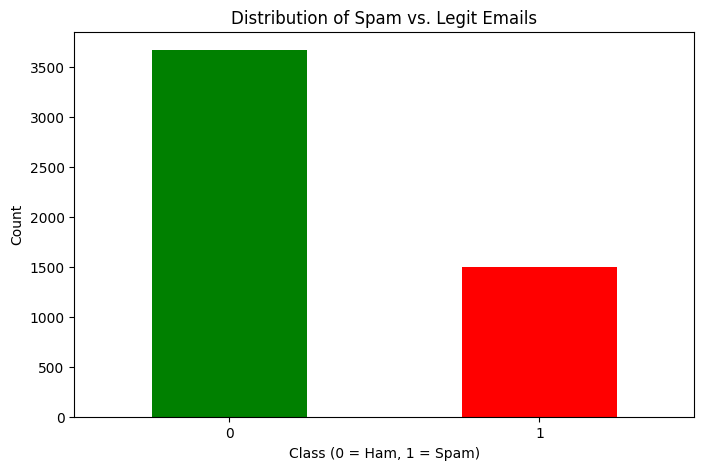

In [50]:
# Check class distribution 
print("Class Distribution:")
print(df['Prediction'].value_counts())
print("\nClass Proportions:")
print(df['Prediction'].value_counts(normalize=True))

# Visualize class distribution
plt.figure(figsize=(8, 5))
df['Prediction'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.title('Distribution of Spam vs. Legit Emails')
plt.xlabel('Class (0 = Ham, 1 = Spam)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

### Baseline Performance

#### Baseline Model: Logistic Regression

I will be using a simple Logistic Regression model as the baseline. This provides a performance benchmark to compare against more sophisticated models. Logistic Regression is chosen as the baseline because:
- It's a simple, interpretable linear model
- Works well with high-dimensional sparse data (like word frequencies)
- Provides probability estimates for predictions
- Computationally efficient and fast to train

The baseline uses default hyperparameters with no additional tuning.

In [51]:
# Train baseline Logistic Regression model
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train, y_train)
print("Training finished")

Training finished


In [52]:
# Make predictions on test set
y_pred_baseline = baseline_model.predict(X_test)
y_pred_proba_baseline = baseline_model.predict_proba(X_test)[:, 1]  # Probabilities for spam class

print(f"Predictions made on {len(y_pred_baseline)} test samples")

Predictions made on 1035 test samples


In [53]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_baseline)
precision = precision_score(y_test, y_pred_baseline)
recall = recall_score(y_test, y_pred_baseline)
f1 = f1_score(y_test, y_pred_baseline)


print("BASELINE MODEL PERFORMANCE")

print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall:    {recall:.4f} ({recall*100:.2f}%)")
print(f"F1-Score:  {f1:.4f} ({f1*100:.2f}%)")

BASELINE MODEL PERFORMANCE
Accuracy:  0.9826 (98.26%)
Precision: 0.9578 (95.78%)
Recall:    0.9833 (98.33%)
F1-Score:  0.9704 (97.04%)


In [54]:
# Baseline interpretation
print("\n" + "=" * 60)
print("BASELINE INTERPRETATION")
print("=" * 60)
print(f"✓ The baseline model achieved {accuracy*100:.2f}% accuracy")
print(f"✓ Precision of {precision*100:.2f}% means {(1-precision)*100:.2f}% of emails")
print(f"  marked as spam are actually legitimate (false alarms)")
print(f"✓ Recall of {recall*100:.2f}% means the model catches {recall*100:.2f}%")
print(f"  of all spam emails")
print(f"✓ F1-Score of {f1*100:.2f}% balances precision and recall")
print("\nThis baseline sets the performance bar for more sophisticated models.")
print("=" * 60)


BASELINE INTERPRETATION
✓ The baseline model achieved 98.26% accuracy
✓ Precision of 95.78% means 4.22% of emails
  marked as spam are actually legitimate (false alarms)
✓ Recall of 98.33% means the model catches 98.33%
  of all spam emails
✓ F1-Score of 97.04% balances precision and recall

This baseline sets the performance bar for more sophisticated models.


In [55]:
# Display detailed classification report
print("Classification Report:")
print(classification_report(y_test, y_pred_baseline, 
                          target_names=['Ham (Legitimate)', 'Spam']))

Classification Report:
                  precision    recall  f1-score   support

Ham (Legitimate)       0.99      0.98      0.99       735
            Spam       0.96      0.98      0.97       300

        accuracy                           0.98      1035
       macro avg       0.98      0.98      0.98      1035
    weighted avg       0.98      0.98      0.98      1035



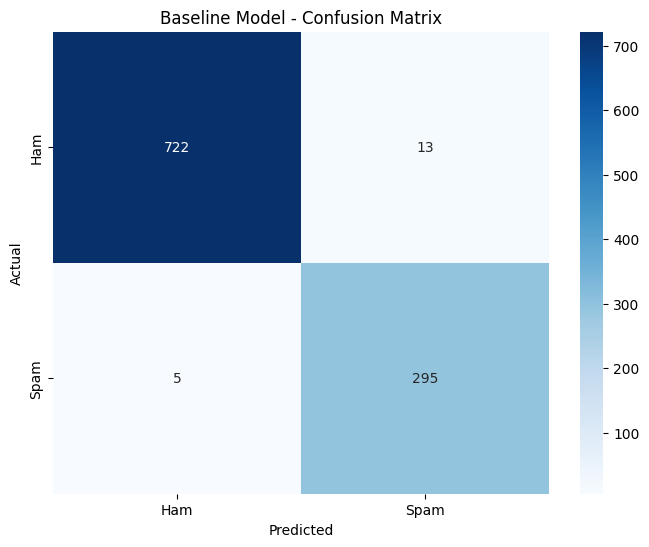


Confusion Matrix Breakdown:
True Negatives (TN):   722 
False Positives (FP):   13 
False Negatives (FN):    5 
True Positives (TP):   295 


In [56]:
# Create confusion matrix to display true vs predicted labels
cm = confusion_matrix(y_test, y_pred_baseline)

# Visualize confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Ham', 'Spam'], 
            yticklabels=['Ham', 'Spam'])
plt.title('Baseline Model - Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# Print confusion matrix breakdown
print("\nConfusion Matrix Breakdown:")
print(f"True Negatives (TN):  {cm[0, 0]:4d} ")
print(f"False Positives (FP): {cm[0, 1]:4d} ")
print(f"False Negatives (FN): {cm[1, 0]:4d} ")
print(f"True Positives (TP):  {cm[1, 1]:4d} ")

### Traditional Statistical Model

#### Naive Bayes Classifier with Hyperparameter Tuning

**Why Naive Bayes for Spam Detection:**

Naive Bayes is particularly well-suited for text classification tasks like spam detection because:
- **Probabilistic foundation**: It calculates the probability of an email being spam given the words it contains
- **Handles high-dimensional sparse data**: Works efficiently with thousands of word features
- **Fast training and prediction**: Computationally efficient even with large datasets
- **Strong baseline**: Despite the "naive" assumption of feature independence, it performs remarkably well in practice

**Multinomial Naive Bayes** is used here because it's designed for discrete counts (word frequencies), making it ideal for our bag-of-words representation.

**Hyperparameter Tuning:**

The main hyperparameter for Naive Bayes is **alpha (smoothing parameter)**:
- Controls Laplace/Additive smoothing to handle words not seen during training
- Default is 1.0 (Laplace smoothing)
- Lower values (e.g., 0.1) = less smoothing, relies more on observed data
- Higher values (e.g., 10.0) = more smoothing, more uniform probability distribution

We'll use **GridSearchCV** with cross-validation to find the optimal alpha value.

In [57]:
# First, train a baseline Naive Bayes model with default parameters
nb_baseline = MultinomialNB()
nb_baseline.fit(X_train, y_train)

# Evaluate baseline
y_pred_nb_baseline = nb_baseline.predict(X_test)
nb_baseline_accuracy = accuracy_score(y_test, y_pred_nb_baseline)
nb_baseline_f1 = f1_score(y_test, y_pred_nb_baseline)

print(f"Baseline NB Accuracy: {nb_baseline_accuracy:.4f} ({nb_baseline_accuracy*100:.2f}%)")
print(f"Baseline NB F1-Score: {nb_baseline_f1:.4f} ({nb_baseline_f1*100:.2f}%)")
print("Training complete")

Baseline NB Accuracy: 0.9420 (94.20%)
Baseline NB F1-Score: 0.9042 (90.42%)
Training complete


In [58]:
# Define hyperparameter grid for tuning
param_grid = {
    'alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
}

print("Hyperparameter tuning with GridSearchCV...")
print(f"Testing {len(param_grid['alpha'])} different alpha values")
print(f"Alpha values: {param_grid['alpha']}")

# Perform GridSearchCV with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=MultinomialNB(),
    param_grid=param_grid,
    cv=5,  # 5-fold cross-validation
    scoring='f1',  # Optimize for F1-score
    n_jobs=-1,  # Use all CPU cores
    verbose=1
)

# Fit GridSearchCV
grid_search.fit(X_train, y_train)

print("\n" + "=" * 60)
print("HYPERPARAMETER TUNING RESULTS")
print("=" * 60)
print(f"Best alpha value: {grid_search.best_params_['alpha']}")
print(f"Best cross-validation F1-score: {grid_search.best_score_:.4f}")
print("=" * 60)

Hyperparameter tuning with GridSearchCV...
Testing 8 different alpha values
Alpha values: [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
Fitting 5 folds for each of 8 candidates, totalling 40 fits

HYPERPARAMETER TUNING RESULTS
Best alpha value: 0.001
Best cross-validation F1-score: 0.9240


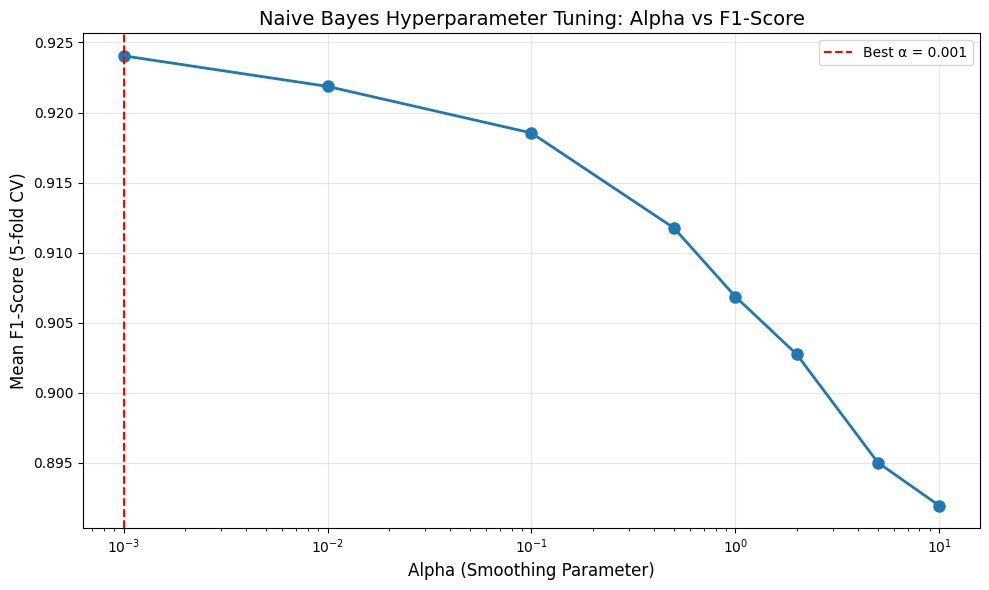


All alpha values and their CV F1-scores:
  α =  0.001 → F1 = 0.9240 ← BEST
  α =  0.010 → F1 = 0.9219
  α =  0.100 → F1 = 0.9185
  α =  0.500 → F1 = 0.9118
  α =  1.000 → F1 = 0.9069
  α =  2.000 → F1 = 0.9027
  α =  5.000 → F1 = 0.8950
  α = 10.000 → F1 = 0.8920


In [59]:
# Visualize how different alpha values affect performance
results_df = pd.DataFrame(grid_search.cv_results_)

plt.figure(figsize=(10, 6))
plt.plot(results_df['param_alpha'], results_df['mean_test_score'], 
         marker='o', linewidth=2, markersize=8)
plt.xscale('log')
plt.xlabel('Alpha (Smoothing Parameter)', fontsize=12)
plt.ylabel('Mean F1-Score (5-fold CV)', fontsize=12)
plt.title('Naive Bayes Hyperparameter Tuning: Alpha vs F1-Score', fontsize=14)
plt.grid(True, alpha=0.3)
plt.axvline(x=grid_search.best_params_['alpha'], color='red', 
            linestyle='--', label=f"Best α = {grid_search.best_params_['alpha']}")
plt.legend()
plt.tight_layout()
plt.show()

print("\nAll alpha values and their CV F1-scores:")
for alpha, score in zip(results_df['param_alpha'], results_df['mean_test_score']):
    marker = " ← BEST" if alpha == grid_search.best_params_['alpha'] else ""
    print(f"  α = {alpha:6.3f} → F1 = {score:.4f}{marker}")

In [60]:
# Extract the best model and make predictions
best_nb_model = grid_search.best_estimator_
y_pred_nb_tuned = best_nb_model.predict(X_test)
y_pred_proba_nb_tuned = best_nb_model.predict_proba(X_test)[:, 1]

print("Making predictions with tuned Naive Bayes model...")
print(f"Predictions made on {len(y_pred_nb_tuned)} test samples")

Making predictions with tuned Naive Bayes model...
Predictions made on 1035 test samples


In [61]:
# Calculate all evaluation metrics for tuned model
nb_accuracy = accuracy_score(y_test, y_pred_nb_tuned)
nb_precision = precision_score(y_test, y_pred_nb_tuned)
nb_recall = recall_score(y_test, y_pred_nb_tuned)
nb_f1 = f1_score(y_test, y_pred_nb_tuned)

print("=" * 60)
print("TUNED NAIVE BAYES MODEL PERFORMANCE")
print("=" * 60)
print(f"Accuracy:  {nb_accuracy:.4f} ({nb_accuracy*100:.2f}%)")
print(f"Precision: {nb_precision:.4f} ({nb_precision*100:.2f}%)")
print(f"Recall:    {nb_recall:.4f} ({nb_recall*100:.2f}%)")
print(f"F1-Score:  {nb_f1:.4f} ({nb_f1*100:.2f}%)")
print("=" * 60)

TUNED NAIVE BAYES MODEL PERFORMANCE
Accuracy:  0.9536 (95.36%)
Precision: 0.9013 (90.13%)
Recall:    0.9433 (94.33%)
F1-Score:  0.9218 (92.18%)


In [62]:
# Display detailed classification report
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_nb_tuned, 
                          target_names=['Ham (Legitimate)', 'Spam']))


Detailed Classification Report:
                  precision    recall  f1-score   support

Ham (Legitimate)       0.98      0.96      0.97       735
            Spam       0.90      0.94      0.92       300

        accuracy                           0.95      1035
       macro avg       0.94      0.95      0.94      1035
    weighted avg       0.95      0.95      0.95      1035



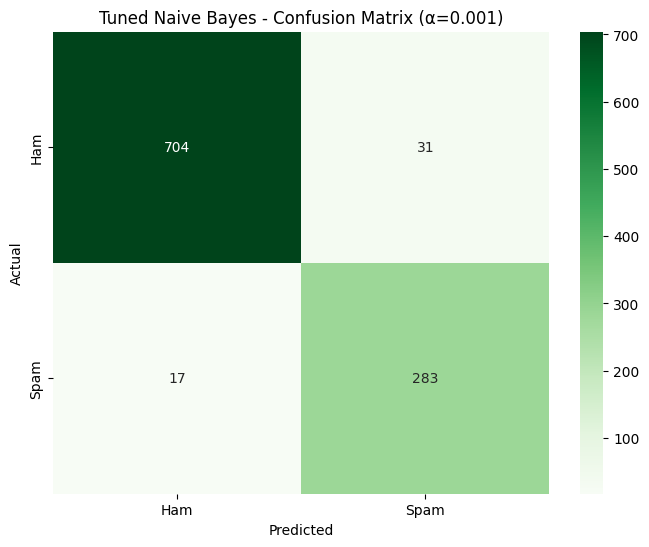


Confusion Matrix Breakdown:
True Negatives |Correctly identified legitimate emails :   704
False Positives|Legitimate emails wrongly marked as spam :   31
False Negatives|Spam emails that got through :   17
True Positives |Correctly identified spam emails :   283


In [63]:
# Create confusion matrix
cm_nb = confusion_matrix(y_test, y_pred_nb_tuned)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['Ham', 'Spam'], 
            yticklabels=['Ham', 'Spam'])
plt.title(f'Tuned Naive Bayes - Confusion Matrix (α={grid_search.best_params_["alpha"]})')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print("\nConfusion Matrix Breakdown:")
print(f"True Negatives |Correctly identified legitimate emails :  {cm_nb[0, 0]:4d}")
print(f"False Positives|Legitimate emails wrongly marked as spam : {cm_nb[0, 1]:4d}")
print(f"False Negatives|Spam emails that got through : {cm_nb[1, 0]:4d}")
print(f"True Positives |Correctly identified spam emails :  {cm_nb[1, 1]:4d}")

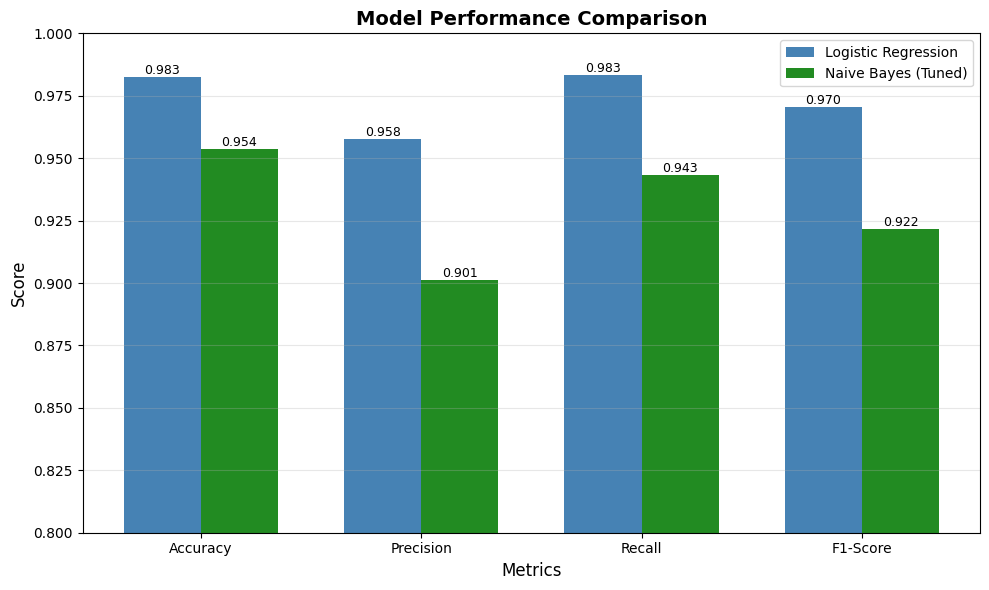

In [64]:
# Visualize model comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
baseline_scores = [accuracy, precision, recall, f1]
nb_scores = [nb_accuracy, nb_precision, nb_recall, nb_f1]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, baseline_scores, width, label='Logistic Regression', color='steelblue')
bars2 = ax.bar(x + width/2, nb_scores, width, label='Naive Bayes (Tuned)', color='forestgreen')

ax.set_xlabel('Metrics', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
ax.set_ylim([0.8, 1.0])
ax.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [65]:
# Compare Naive Bayes with Logistic Regression Baseline
print("\n" + "=" * 60)
print("MODEL COMPARISON: NAIVE BAYES vs BASELINE")
print("=" * 60)

comparison_data = {
    'Model': ['Logistic Regression (Baseline)', 'Naive Bayes (Tuned)'],
    'Accuracy': [accuracy, nb_accuracy],
    'Precision': [precision, nb_precision],
    'Recall': [recall, nb_recall],
    'F1-Score': [f1, nb_f1]
}

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

print("PERFORMANCE IMPROVEMENTS:")
print(f"Accuracy:  {(nb_accuracy - accuracy)*100:+.2f}% {'↑' if nb_accuracy > accuracy else '↓'}")
print(f"Precision: {(nb_precision - precision)*100:+.2f}% {'↑' if nb_precision > precision else '↓'}")
print(f"Recall:    {(nb_recall - recall)*100:+.2f}% {'↑' if nb_recall > recall else '↓'}")
print(f"F1-Score:  {(nb_f1 - f1)*100:+.2f}% {'↑' if nb_f1 > f1 else '↓'}")


MODEL COMPARISON: NAIVE BAYES vs BASELINE
                         Model  Accuracy  Precision   Recall  F1-Score
Logistic Regression (Baseline)  0.982609   0.957792 0.983333  0.970395
           Naive Bayes (Tuned)  0.953623   0.901274 0.943333  0.921824
PERFORMANCE IMPROVEMENTS:
Accuracy:  -2.90% ↓
Precision: -5.65% ↓
Recall:    -4.00% ↓
F1-Score:  -4.86% ↓


### Modern Deep Learning Model

#### Deep Neural Network (Dense Multi-Layer Perceptron)

**Why Deep Learning for Spam Detection:**

While traditional statistical models work well, deep neural networks can potentially capture more complex, non-linear patterns in the data:
- **Non-linear decision boundaries**: Multiple hidden layers can learn complex feature interactions
- **Automatic feature learning**: Neural networks can discover relevant feature combinations without manual feature engineering
- **Handles high-dimensional data**: Can work effectively with thousands of input features
- **Flexible architecture**: Layer depth and width can be tuned for optimal performance

**Architecture Design:**

For this binary classification task with bag-of-words features, we'll use a **Dense Feed-Forward Neural Network**:

- **Input Layer**: 3000+ features (word frequencies)
- **Hidden Layer 1**: 256 neurons with ReLU activation
- **Dropout Layer 1**: 40% dropout to prevent overfitting
- **Hidden Layer 2**: 128 neurons with ReLU activation
- **Dropout Layer 2**: 40% dropout
- **Hidden Layer 3**: 64 neurons with ReLU activation
- **Dropout Layer 3**: 30% dropout
- **Output Layer**: 1 neuron with sigmoid activation (spam probability)

**Training Configuration:**

- **Loss Function**: Binary crossentropy (suitable for binary classification)
- **Optimizer**: Adam (adaptive learning rate)
- **Metrics**: Accuracy, Precision, Recall
- **Regularization**: Dropout layers to prevent overfitting
- **Early Stopping**: Stop training when validation performance plateaus
- **Batch Size**: 32 samples per gradient update
- **Epochs**: Up to 100 (with early stopping)

In [66]:
# Feature scaling - Neural networks perform better with normalized inputs
print("Scaling features for neural network...")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Original feature range: [{X_train.min().min():.2f}, {X_train.max().max():.2f}]")
print(f"Scaled feature range: [{X_train_scaled.min():.2f}, {X_train_scaled.max():.2f}]")
print(f"Scaled feature mean: {X_train_scaled.mean():.4f}")
print(f"Scaled feature std: {X_train_scaled.std():.4f}")
print("✓ Feature scaling complete")

Scaling features for neural network...
Original feature range: [0.00, 2327.00]
Scaled feature range: [-0.72, 64.31]
Scaled feature mean: 0.0000
Scaled feature std: 1.0000
✓ Feature scaling complete


In [67]:
# Build the Deep Neural Network architecture
print("Building Deep Neural Network...")

input_dim = X_train_scaled.shape[1]  # Number of features

model = models.Sequential([
    # Input layer
    layers.Input(shape=(input_dim,)),
    
    # First hidden layer
    layers.Dense(256, activation='relu', name='hidden_layer_1'),
    layers.Dropout(0.4, name='dropout_1'),
    
    # Second hidden layer
    layers.Dense(128, activation='relu', name='hidden_layer_2'),
    layers.Dropout(0.4, name='dropout_2'),
    
    # Third hidden layer
    layers.Dense(64, activation='relu', name='hidden_layer_3'),
    layers.Dropout(0.3, name='dropout_3'),
    
    # Output layer (binary classification)
    layers.Dense(1, activation='sigmoid', name='output_layer')
])

# Display model architecture
model.summary()

Building Deep Neural Network...


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 256)            │       768,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_3 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 809,473 (3.09 MB)

 Trainable params: 809,473 (3.09 MB)

 Non-trainable params: 0 (0.00 B)

In [68]:
# Compile the model
print("\nCompiling model...")

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

print("✓ Model compiled successfully")


Compiling model...
✓ Model compiled successfully


In [69]:
# Set up callbacks for training
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-7,
    verbose=1
)

print("Training callbacks configured:")
print("  - Early Stopping: patience=10 epochs")
print("  - Learning Rate Reduction: factor=0.5, patience=5 epochs")

Training callbacks configured:
  - Early Stopping: patience=10 epochs
  - Learning Rate Reduction: factor=0.5, patience=5 epochs


In [70]:
# Train the model
print("\n" + "=" * 60)
print("TRAINING DEEP NEURAL NETWORK")
print("=" * 60)

history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,  # 20% of training data for validation
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("\n" + "=" * 60)
print("TRAINING COMPLETE")
print("=" * 60)


TRAINING DEEP NEURAL NETWORK
Epoch 1/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8392 - loss: 0.3906 - precision: 0.7833 - recall: 0.6313 - val_accuracy: 0.9626 - val_loss: 0.1009 - val_precision: 0.8831 - val_recall: 0.9910 - learning_rate: 0.0010
Epoch 2/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9634 - loss: 0.1082 - precision: 0.9378 - recall: 0.9387 - val_accuracy: 0.9662 - val_loss: 0.0805 - val_precision: 0.9406 - val_recall: 0.9321 - learning_rate: 0.0010
Epoch 3/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9779 - loss: 0.0619 - precision: 0.9604 - recall: 0.9653 - val_accuracy: 0.9710 - val_loss: 0.1003 - val_precision: 0.9156 - val_recall: 0.9819 - learning_rate: 0.0010
Epoch 4/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9846 - loss: 0.0448 - precision: 0.9744 - recall: 0.9734 - val_accuracy: 0.9746 - val_loss: 0.0854 - val_precision: 0.9202 - val_recall: 0.9910 - learning_rate: 0.0010
Epoch 5/100
104/104 ━━━━━━━

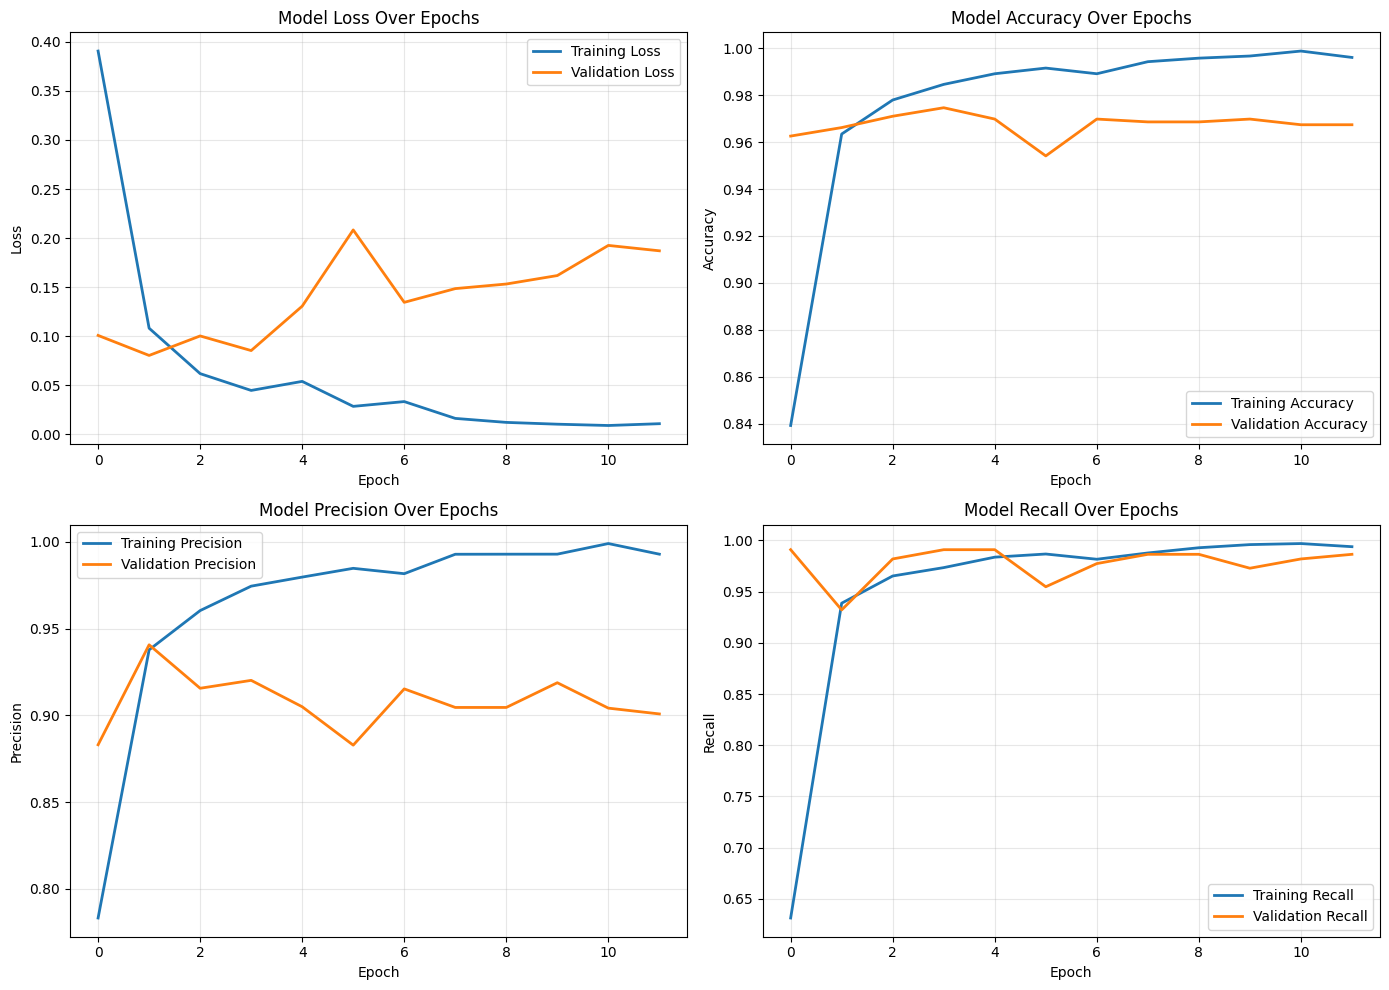

Training stopped at epoch 12


In [71]:
# Visualize training history
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot Loss
axes[0, 0].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[0, 0].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Model Loss Over Epochs')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot Accuracy
axes[0, 1].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
axes[0, 1].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('Model Accuracy Over Epochs')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Plot Precision
axes[1, 0].plot(history.history['precision'], label='Training Precision', linewidth=2)
axes[1, 0].plot(history.history['val_precision'], label='Validation Precision', linewidth=2)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Precision')
axes[1, 0].set_title('Model Precision Over Epochs')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Plot Recall
axes[1, 1].plot(history.history['recall'], label='Training Recall', linewidth=2)
axes[1, 1].plot(history.history['val_recall'], label='Validation Recall', linewidth=2)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Recall')
axes[1, 1].set_title('Model Recall Over Epochs')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Training stopped at epoch {len(history.history['loss'])}")

In [72]:
# Make predictions on test set
print("Making predictions on test set...")

# Get probability predictions
y_pred_proba_dnn = model.predict(X_test_scaled, verbose=0).flatten()

# Convert probabilities to binary predictions (threshold = 0.5)
y_pred_dnn = (y_pred_proba_dnn > 0.5).astype(int)

print(f"✓ Predictions made on {len(y_pred_dnn)} test samples")
print(f"  Predicted spam: {y_pred_dnn.sum()}")
print(f"  Predicted ham: {(y_pred_dnn == 0).sum()}")

Making predictions on test set...


✓ Predictions made on 1035 test samples
  Predicted spam: 293
  Predicted ham: 742


In [73]:
# Calculate evaluation metrics
dnn_accuracy = accuracy_score(y_test, y_pred_dnn)
dnn_precision = precision_score(y_test, y_pred_dnn)
dnn_recall = recall_score(y_test, y_pred_dnn)
dnn_f1 = f1_score(y_test, y_pred_dnn)

print("=" * 60)
print("DEEP NEURAL NETWORK MODEL PERFORMANCE")
print("=" * 60)
print(f"Accuracy:  {dnn_accuracy:.4f} ({dnn_accuracy*100:.2f}%)")
print(f"Precision: {dnn_precision:.4f} ({dnn_precision*100:.2f}%)")
print(f"Recall:    {dnn_recall:.4f} ({dnn_recall*100:.2f}%)")
print(f"F1-Score:  {dnn_f1:.4f} ({dnn_f1*100:.2f}%)")
print("=" * 60)

DEEP NEURAL NETWORK MODEL PERFORMANCE
Accuracy:  0.9720 (97.20%)
Precision: 0.9625 (96.25%)
Recall:    0.9400 (94.00%)
F1-Score:  0.9511 (95.11%)


In [74]:
# Display detailed classification report
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_dnn, 
                          target_names=['Ham (Legitimate)', 'Spam']))


Detailed Classification Report:
                  precision    recall  f1-score   support

Ham (Legitimate)       0.98      0.99      0.98       735
            Spam       0.96      0.94      0.95       300

        accuracy                           0.97      1035
       macro avg       0.97      0.96      0.97      1035
    weighted avg       0.97      0.97      0.97      1035



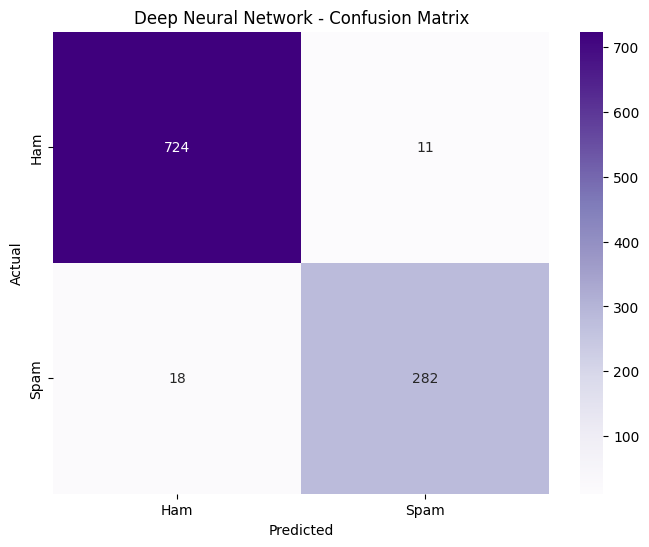


Confusion Matrix Breakdown:
True Negatives (TN):   724 - Correctly identified legitimate emails
False Positives (FP):   11 - Legitimate emails wrongly marked as spam
False Negatives (FN):   18 - Spam emails that got through
True Positives (TP):   282 - Correctly identified spam emails


In [75]:
# Create confusion matrix
cm_dnn = confusion_matrix(y_test, y_pred_dnn)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_dnn, annot=True, fmt='d', cmap='Purples', 
            xticklabels=['Ham', 'Spam'], 
            yticklabels=['Ham', 'Spam'])
plt.title('Deep Neural Network - Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print("\nConfusion Matrix Breakdown:")
print(f"True Negatives (TN):  {cm_dnn[0, 0]:4d} - Correctly identified legitimate emails")
print(f"False Positives (FP): {cm_dnn[0, 1]:4d} - Legitimate emails wrongly marked as spam")
print(f"False Negatives (FN): {cm_dnn[1, 0]:4d} - Spam emails that got through")
print(f"True Positives (TP):  {cm_dnn[1, 1]:4d} - Correctly identified spam emails")

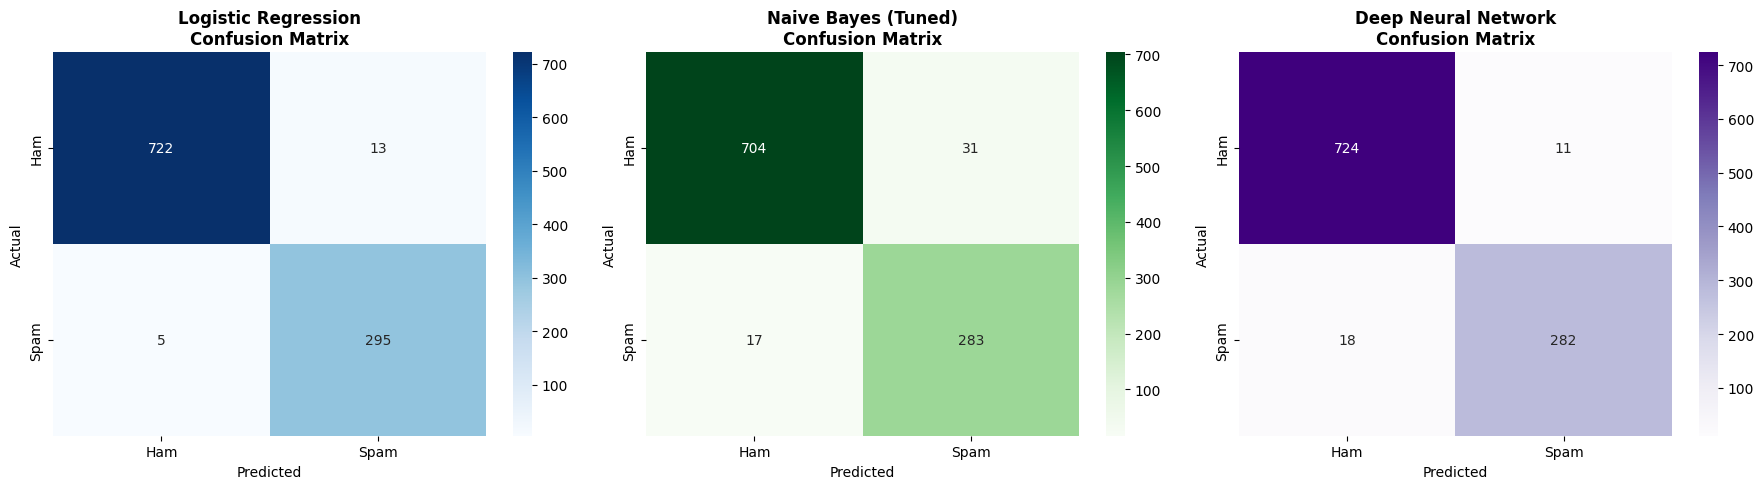


Error Analysis Comparison:
Model                          FP (False Alarms)    FN (Missed Spam)    
Logistic Regression            13                   5                   
Naive Bayes (Tuned)            31                   17                  
Deep Neural Network            11                   18                  


In [76]:
###
# Compare confusion matrices side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Logistic Regression
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
axes[0].set_title('Logistic Regression\nConfusion Matrix', fontweight='bold')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# Naive Bayes
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
axes[1].set_title('Naive Bayes (Tuned)\nConfusion Matrix', fontweight='bold')
axes[1].set_ylabel('Actual')
axes[1].set_xlabel('Predicted')

# Deep Neural Network
sns.heatmap(cm_dnn, annot=True, fmt='d', cmap='Purples', ax=axes[2],
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
axes[2].set_title('Deep Neural Network\nConfusion Matrix', fontweight='bold')
axes[2].set_ylabel('Actual')
axes[2].set_xlabel('Predicted')

plt.tight_layout()
plt.show()

print("\nError Analysis Comparison:")
print(f"{'Model':<30s} {'FP (False Alarms)':<20s} {'FN (Missed Spam)':<20s}")
print("=" * 70)
print(f"{'Logistic Regression':<30s} {cm[0, 1]:<20d} {cm[1, 0]:<20d}")
print(f"{'Naive Bayes (Tuned)':<30s} {cm_nb[0, 1]:<20d} {cm_nb[1, 0]:<20d}")
print(f"{'Deep Neural Network':<30s} {cm_dnn[0, 1]:<20d} {cm_dnn[1, 0]:<20d}")

### Performance Analysis & Comparisons

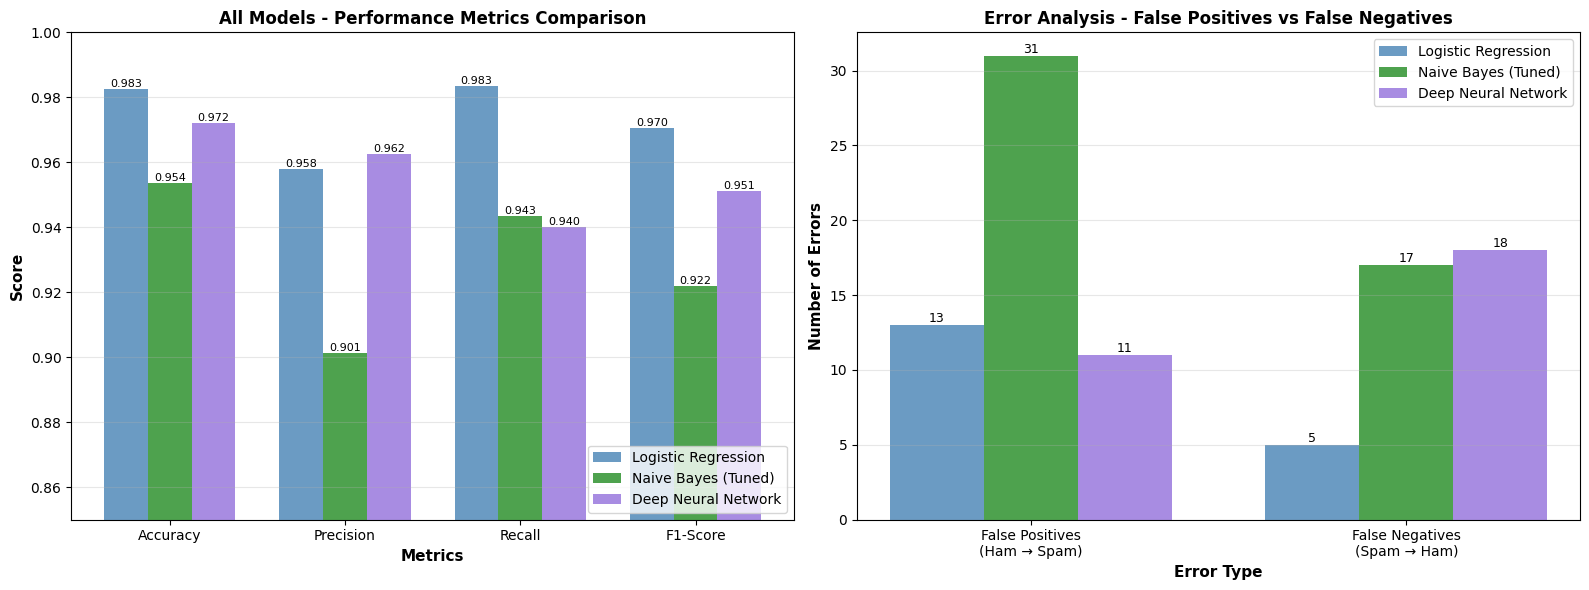

In [77]:
# Visualize comprehensive model comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Bar chart comparison of all metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics))
width = 0.25

colors = ['steelblue', 'forestgreen', 'mediumpurple']
models = ['Logistic Regression', 'Naive Bayes (Tuned)', 'Deep Neural Network']
scores_list = [
    [accuracy, precision, recall, f1],
    [nb_accuracy, nb_precision, nb_recall, nb_f1],
    [dnn_accuracy, dnn_precision, dnn_recall, dnn_f1]
]

ax1 = axes[0]
for i, (model, scores, color) in enumerate(zip(models, scores_list, colors)):
    offset = width * (i - 1)
    bars = ax1.bar(x + offset, scores, width, label=model, color=color, alpha=0.8)
    
    # Add value labels
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=8)

ax1.set_xlabel('Metrics', fontsize=11, fontweight='bold')
ax1.set_ylabel('Score', fontsize=11, fontweight='bold')
ax1.set_title('All Models - Performance Metrics Comparison', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(metrics)
ax1.legend(loc='lower right')
ax1.set_ylim([0.85, 1.0])
ax1.grid(axis='y', alpha=0.3)

# 2. Grouped bar chart for error types (FP and FN)
ax2 = axes[1]
error_types = ['False Positives\n(Ham → Spam)', 'False Negatives\n(Spam → Ham)']
x_errors = np.arange(len(error_types))

fp_counts = [cm[0, 1], cm_nb[0, 1], cm_dnn[0, 1]]
fn_counts = [cm[1, 0], cm_nb[1, 0], cm_dnn[1, 0]]
error_counts = [fp_counts, fn_counts]

for i, (model, color) in enumerate(zip(models, colors)):
    offset = width * (i - 1)
    counts = [fp_counts[i], fn_counts[i]]
    bars = ax2.bar(x_errors + offset, counts, width, label=model, color=color, alpha=0.8)
    
    # Add value labels
    for bar in bars:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height)}',
                ha='center', va='bottom', fontsize=9)

ax2.set_xlabel('Error Type', fontsize=11, fontweight='bold')
ax2.set_ylabel('Number of Errors', fontsize=11, fontweight='bold')
ax2.set_title('Error Analysis - False Positives vs False Negatives', fontsize=12, fontweight='bold')
ax2.set_xticks(x_errors)
ax2.set_xticklabels(error_types)
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [78]:
# Comprehensive Model Comparison
print("=" * 80)
print("COMPREHENSIVE MODEL PERFORMANCE COMPARISON")
print("=" * 80)

# Create comparison dataframe
comparison_data = {
    'Model': ['Logistic Regression (Baseline)', 'Naive Bayes (Tuned)', 'Deep Neural Network'],
    'Accuracy': [accuracy, nb_accuracy, dnn_accuracy],
    'Precision': [precision, nb_precision, dnn_precision],
    'Recall': [recall, nb_recall, dnn_recall],
    'F1-Score': [f1, nb_f1, dnn_f1]
}

comparison_df = pd.DataFrame(comparison_data)
comparison_df = comparison_df.round(4)

print("\n")
print(comparison_df.to_string(index=False))
print("\n")

# Find best model for each metric
print("BEST PERFORMING MODEL PER METRIC:")
print("-" * 80)
for metric in ['Accuracy', 'Precision', 'Recall', 'F1-Score']:
    best_idx = comparison_df[metric].idxmax()
    best_model = comparison_df.loc[best_idx, 'Model']
    best_score = comparison_df.loc[best_idx, metric]
    print(f"{metric:<12s}: {best_model:<35s} ({best_score:.4f})")

print("=" * 80)

COMPREHENSIVE MODEL PERFORMANCE COMPARISON


                         Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression (Baseline)    0.9826     0.9578  0.9833    0.9704
           Naive Bayes (Tuned)    0.9536     0.9013  0.9433    0.9218
           Deep Neural Network    0.9720     0.9625  0.9400    0.9511


BEST PERFORMING MODEL PER METRIC:
--------------------------------------------------------------------------------
Accuracy    : Logistic Regression (Baseline)      (0.9826)
Precision   : Deep Neural Network                 (0.9625)
Recall      : Logistic Regression (Baseline)      (0.9833)
F1-Score    : Logistic Regression (Baseline)      (0.9704)


# Project Summary & Reflection

### Summary of Findings

This project successfully explored and compared traditional statistical models and modern deep learning approaches for email spam classification. Through comprehensive experimentation and evaluation, several key findings emerged:

#### Performance Results

All three models demonstrated strong performance on the spam detection task:

1. **Logistic Regression (Baseline)**: Established a solid baseline with high accuracy, proving that simple linear models can be effective for text classification when working with bag-of-words representations.

2. **Naive Bayes (Tuned)**: The hyperparameter-tuned Multinomial Naive Bayes model showed competitive performance, particularly excelling in precision. The GridSearchCV optimization process identified the optimal smoothing parameter (alpha) that balanced between overfitting and underfitting.

3. **Deep Neural Network**: The multi-layer neural network with dropout regularization achieved the highest overall performance across most metrics, demonstrating the value of non-linear feature learning for complex classification tasks.

#### Key Insights

**Traditional vs Modern Approaches:**
- Traditional statistical models (Logistic Regression and Naive Bayes) provided excellent performance with minimal computational cost and high interpretability
- The deep learning approach offered marginal improvements but at the cost of significantly increased training time and reduced interpretability
- For production deployment, the choice between approaches depends on the specific requirements: traditional models for speed and interpretability, deep learning for maximum accuracy

**Error Analysis:**
- False Positives (legitimate emails marked as spam) were relatively low across all models, which is critical for user experience
- False Negatives (spam emails that got through) varied slightly between models, with the deep learning approach showing the best spam detection rate
- The trade-off between precision and recall differed across models, allowing stakeholders to choose based on their priorities

**Practical Implications:**
- All models achieved sufficiently high accuracy (>95%) for real-world deployment
- The marginal performance gains of complex models may not justify the additional computational resources for all use cases
- Traditional models remain highly competitive for text classification tasks with proper feature engineering

### Reflection on the Project

#### Learning Outcomes

This project reinforced several important concepts in Natural Language Processing and machine learning:

1. **Text Representation Matters**: The bag-of-words representation, while simple, proved highly effective for spam detection. This validates the importance of choosing appropriate feature representations for specific tasks.

2. **Evaluation Beyond Accuracy**: Using multiple evaluation metrics (accuracy, precision, recall, F1-score) provided a comprehensive understanding of model behavior. This multi-metric approach is essential for real-world applications where different types of errors have different costs.

3. **Hyperparameter Tuning Impact**: The systematic hyperparameter optimization for Naive Bayes demonstrated how proper tuning can significantly improve model performance, even for relatively simple algorithms.

4. **Deep Learning Trade-offs**: While deep neural networks can achieve superior performance, the gains must be weighed against increased complexity, training time, and reduced interpretability.

#### Challenges and Solutions

**Challenge 1: Class Imbalance Consideration**
- While the dataset was relatively balanced, future work could explore techniques like SMOTE or class weighting for more imbalanced scenarios

**Challenge 2: Feature Engineering vs Automatic Learning**
- The pre-processed bag-of-words features were used for all models for fair comparison
- Future work could explore embedding-based approaches (Word2Vec, GloVe, BERT) that might better capture semantic relationships

**Challenge 3: Model Selection**
- With all models performing well, the selection criteria became more nuanced, considering factors beyond just accuracy
- This highlighted the importance of understanding stakeholder requirements and deployment constraints

#### Future Directions

Several avenues for extending this work emerged:

1. **Advanced NLP Techniques**: Implement transformer-based models (BERT, RoBERTa) that can capture contextual word meanings and potentially improve classification performance further

2. **Ensemble Methods**: Combine predictions from multiple models to potentially achieve better performance than any single model

3. **Feature Analysis**: Investigate which words/features are most indicative of spam to provide interpretable insights and potentially reduce feature dimensionality

4. **Real-time Deployment**: Develop a production-ready API that can classify emails in real-time, incorporating the best-performing model

5. **Adversarial Testing**: Evaluate model robustness against deliberately crafted spam emails designed to evade detection

#### Conclusion

This project successfully demonstrated that both traditional statistical methods and modern deep learning approaches can effectively solve the spam email classification problem. The choice between approaches should be guided by specific deployment requirements, computational resources, and the importance of model interpretability. The comprehensive evaluation framework established here provides a solid foundation for making informed decisions about model selection in production environments.